# Project 26 — Card-Fraud Triage: GMM Density Scoring vs Autoencoder Anomaly Detector

**Team T068 · Section B** — Sharma Piyush (2401010437) · Saransh Singh Tomar (2401010418) · Satwik Mani Tripathi (2401020056) · Gourav Tanwar (2401010173) · Alok Kumar (2401010058)
## Notebook 01: Data Quality, Exploratory Data Analysis and Feature Engineering

**Title:** *Card-Fraud Triage: GMM Density Scoring vs Autoencoder Anomaly Detector*

**Goal of the project.** Treat card fraud as **anomaly detection**: learn what *legitimate* transactions look like
(without ever showing fraud labels to the models) and send the least "normal-looking" transactions to a human
review queue. Phase 1 uses a **Gaussian Mixture Model** (density score); Phase 2 uses an **Autoencoder**
(reconstruction-error score) and a **hybrid** of the two.

**This notebook** answers: *What is in the data? Is it clean? How rare is fraud? How should we split it? Which
features should the models see, and in what form?* Every decision made here is reused unchanged in Notebooks 02–04.

| Item | Value |
|---|---|
| Dataset | Credit Card Fraud Detection — ULB Machine Learning Group / Kaggle (Dal Pozzolo et al., 2015) |
| Rows | 284,807 card transactions made by European cardholders over two days (Sept 2013) |
| Features | `Time`, `Amount`, and `V1`–`V28` (PCA components; original features are confidential) |
| Label | `Class` = 1 for fraud, 0 for legitimate |

> Runs top-to-bottom on Google Colab (CPU is enough). The dataset is downloaded automatically.

## 0. Setup
Shared helper code (identical in all four notebooks): download + checksum, chronological split, feature
engineering, and the triage metrics.

In [1]:
# ============================================================
# Common setup — identical in every notebook of Project 26
# (data download, chronological split, features, metrics, plots)
# ============================================================
import os, sys, json, time, hashlib, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer, QuantileTransformer
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
IN_COLAB = "google.colab" in sys.modules

# ---------- paths ----------
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"  # public mirror of the ULB/Kaggle file
DATA_SHA256 = "76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89"
DATA_PATH = Path(os.environ.get("FRAUD_DATA", "creditcard.csv"))
OUT = Path(os.environ.get("FRAUD_OUT", "outputs"))
FIG, RES = OUT / "figures", OUT / "results"
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)

# ---------- plotting ----------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
C_LEGIT, C_FRAUD = "#4C72B0", "#C44E52"


def savefig(name):
    """Save the current figure into outputs/figures (used by the IEEE report)."""
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")


def save_json(obj, name):
    def conv(o):
        if isinstance(o, dict):
            return {str(k): conv(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)):
            return [conv(v) for v in o]
        if isinstance(o, np.generic):
            return o.item()
        return o
    (RES / name).write_text(json.dumps(conv(obj), indent=2))


# ---------- data ----------
def download_data(path=DATA_PATH):
    """Download the ULB credit-card dataset (once) and verify its checksum."""
    if not path.exists():
        print("Downloading dataset (~150 MB) ...")
        urllib.request.urlretrieve(DATA_URL, path)
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha == DATA_SHA256, "checksum mismatch - the file is not the original dataset"
    return path


def load_data():
    """Read the CSV, drop exact duplicate rows, order by Time."""
    df = pd.read_csv(download_data())
    info = {"rows_raw": len(df), "frauds_raw": int(df.Class.sum())}
    dup = df.duplicated(keep="first")
    info.update(duplicates_dropped=int(dup.sum()), fraud_duplicates_dropped=int(df.loc[dup, "Class"].sum()))
    df = df.loc[~dup].sort_values("Time", kind="stable").reset_index(drop=True)
    info.update(rows=len(df), frauds=int(df.Class.sum()))
    return df, info


def chronological_split(df, fractions=(0.6, 0.2, 0.2)):
    """Consecutive time blocks: train (past) -> validation -> test (future)."""
    n = len(df)
    a, b = int(round(fractions[0] * n)), int(round((fractions[0] + fractions[1]) * n))
    return df.iloc[:a].copy(), df.iloc[a:b].copy(), df.iloc[b:].copy()


# ---------- features ----------
V_COLS = [f"V{i}" for i in range(1, 29)]
FEATURE_SETS = {
    "pca": V_COLS,
    "pca+amount": V_COLS + ["log_amount"],
    "full": V_COLS + ["log_amount", "hour_sin", "hour_cos"],
}


def add_features(df):
    """log(1+Amount) and time-of-day on the unit circle; raw Time is dropped."""
    out = df.copy()
    out["log_amount"] = np.log1p(out["Amount"])
    out["hour"] = (out["Time"] % 86400) / 3600.0
    out["hour_sin"] = np.sin(2 * np.pi * out["hour"] / 24)
    out["hour_cos"] = np.cos(2 * np.pi * out["hour"] / 24)
    return out


def make_scaler(kind):
    return {
        "standard": StandardScaler(),
        "robust": RobustScaler(),
        "power": PowerTransformer(method="yeo-johnson", standardize=True),
        "quantile": QuantileTransformer(output_distribution="normal", n_quantiles=1000, subsample=200_000, random_state=SEED),
    }[kind]


class Preprocessor:
    """Select a feature set and scale it. Fitted on LEGITIMATE TRAINING rows only."""

    def __init__(self, feature_set="full", scaler="standard"):
        self.cols, self.kind = FEATURE_SETS[feature_set], scaler
        self.scaler = make_scaler(scaler)

    def fit(self, df_legit):
        assert df_legit["Class"].sum() == 0, "fit on legitimate rows only"
        self.scaler.fit(df_legit[self.cols])
        return self

    def transform(self, df):
        return self.scaler.transform(df[self.cols]).astype(np.float32)


# ---------- triage metrics (higher score = more suspicious) ----------
FPR_BUDGETS = (0.001, 0.005, 0.01)   # 0.1 %, 0.5 %, 1 % of legitimate customers wrongly flagged
CAPACITIES = (50, 100, 200, 500)       # alerts an analyst team can review


def pr_auc(y, s):
    return float(average_precision_score(y, s))


def threshold_at_fpr(y, s, fpr):
    """Smallest threshold whose false-positive rate on (y, s) is <= fpr."""
    neg = np.sort(np.asarray(s)[np.asarray(y) == 0])
    idx = min(max(int(np.ceil((1 - fpr) * len(neg))) - 1, 0), len(neg) - 1)
    return float(neg[idx])


def confusion_at(y, s, thr):
    y, flag = np.asarray(y), np.asarray(s) > thr
    tp, fp = int((flag & (y == 1)).sum()), int((flag & (y == 0)).sum())
    fn, tn = int((~flag & (y == 1)).sum()), int((~flag & (y == 0)).sum())
    return dict(threshold=float(thr), alerts=tp + fp, tp=tp, fp=fp, fn=fn, tn=tn,
                precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), fpr=fp / max(fp + tn, 1))


def at_capacity(y, s, k):
    top = np.argsort(-np.asarray(s), kind="stable")[:k]
    tp = int(np.asarray(y)[top].sum())
    return dict(k=k, tp=tp, precision=tp / k, recall=tp / max(int(np.sum(y)), 1))


def bootstrap_ci(y, s, n_boot=1000, seed=SEED):
    """Stratified bootstrap 95 % interval for PR-AUC."""
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    vals = [pr_auc(y[i], s[i]) for i in
            (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n_boot))]
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def paired_bootstrap(y, s_a, s_b, n_boot=1000, seed=SEED):
    """PR-AUC(a) - PR-AUC(b) on identical resamples -> difference, 95 % CI, P(a <= b)."""
    rng = np.random.default_rng(seed)
    y, s_a, s_b = map(np.asarray, (y, s_a, s_b))
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    d = []
    for _ in range(n_boot):
        i = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        d.append(pr_auc(y[i], s_a[i]) - pr_auc(y[i], s_b[i]))
    d = np.asarray(d)
    return dict(diff=pr_auc(y, s_a) - pr_auc(y, s_b), ci=[float(np.quantile(d, .025)), float(np.quantile(d, .975))],
                p_not_better=float((d <= 0).mean()))


def evaluate(name, y_val, s_val, y_test, s_test, n_boot=1000):
    """Thresholds are chosen on VALIDATION, then applied unchanged to TEST."""
    r = dict(model=name, val_pr_auc=pr_auc(y_val, s_val), test_pr_auc=pr_auc(y_test, s_test),
             test_roc_auc=float(roc_auc_score(y_test, s_test)), test_pr_auc_ci=bootstrap_ci(y_test, s_test, n_boot),
             base_rate=float(np.mean(y_test)), budgets={}, capacity={})
    for f in FPR_BUDGETS:
        r["budgets"][f] = confusion_at(y_test, s_test, threshold_at_fpr(y_val, s_val, f))
    for k in CAPACITIES:
        r["capacity"][k] = at_capacity(y_test, s_test, k)
    return r


def summary_table(reports):
    rows = []
    for r in reports:
        row = {"model": r["model"], "val PR-AUC": r["val_pr_auc"], "test PR-AUC": r["test_pr_auc"],
               "95% CI": "[{:.3f}, {:.3f}]".format(*r["test_pr_auc_ci"]), "test ROC-AUC": r["test_roc_auc"]}
        for f, b in r["budgets"].items():
            row[f"Recall@FPR{float(f)*100:g}%"] = b["recall"]
            row[f"real FPR{float(f)*100:g}%"] = b["fpr"]
        for k, c in r["capacity"].items():
            row[f"P@{k}"] = c["precision"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


def plot_pr_curves(y, scores, title, name=None, ax=None):
    """Precision-recall curves for several scorers on the same labels."""
    ax = ax or plt.subplots(figsize=(6.5, 4.8))[1]
    for label, s in scores.items():
        p, r, _ = precision_recall_curve(y, s)
        ax.plot(r, p, lw=1.8, label=f"{label} (AP={pr_auc(y, s):.3f})")
    ax.axhline(np.mean(y), ls="--", c="grey", lw=1, label=f"base rate = {np.mean(y):.4f}")
    ax.set(xlabel="Recall", ylabel="Precision", title=title, xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8, loc="upper right")
    if name:
        savefig(name)
    return ax


def finish_colab(zip_name):
    """On Colab: zip outputs/ and download it so figures/results can go into the repo."""
    if IN_COLAB:
        import shutil
        from google.colab import files
        shutil.make_archive(zip_name, "zip", OUT)
        files.download(f"{zip_name}.zip")
    else:
        print("Outputs saved in", OUT.resolve())

## 1. Data quality

In [2]:
raw = pd.read_csv(download_data())
print("shape:", raw.shape)
print("missing values:", int(raw.isna().sum().sum()))
print("dtypes:", raw.dtypes.value_counts().to_dict())
print("Time sorted ascending:", raw["Time"].is_monotonic_increasing)
dups = raw.duplicated(keep="first")
print(f"exact duplicate rows: {dups.sum()}  (of which fraud: {raw.loc[dups, 'Class'].sum()})")
raw.describe().T[["mean", "std", "min", "50%", "max"]].round(3).head(12)

shape: (284807, 31)
missing values: 0
dtypes: {dtype('float64'): 30, dtype('int64'): 1}
Time sorted ascending: True
exact duplicate rows: 1081  (of which fraud: 19)


,mean,std,min,50%,max
Time,94813.86,47488.146,0.000,84692.000,172792.000
V1,0.00,1.959,-56.408,0.018,2.455
V2,0.00,1.651,-72.716,0.065,22.058
V3,-0.00,1.516,-48.326,0.180,9.383
V4,0.00,1.416,-5.683,-0.020,16.875
V5,0.00,1.380,-113.743,-0.054,34.802
V6,0.00,1.332,-26.161,-0.274,73.302
V7,-0.00,1.237,-43.557,0.040,120.589
V8,0.00,1.194,-73.217,0.022,20.007
V9,-0.00,1.099,-13.434,-0.051,15.595


**Decisions.**
* There are **no missing values** and all columns are numeric, so no imputation is needed.
* Exact duplicate rows are removed **once, before splitting**. Otherwise the same row could appear in both train and
  test, which leaks information and inflates scores.
* `V1`–`V28` are already centred PCA scores. Their variances fall from V1 to V28 because PCA orders components by
  variance. `Amount` and `Time` are on raw scales.

In [3]:
df, info = load_data()
info

{'rows_raw': 284807,
 'frauds_raw': 492,
 'duplicates_dropped': 1081,
 'fraud_duplicates_dropped': 19,
 'rows': 283726,
 'frauds': 473}

## 2. Class imbalance — why accuracy is useless here

fraud: 473 / 283726 = 0.167 %  (1 fraud per 600 transactions)
accuracy of a model that NEVER flags fraud: 99.833 %


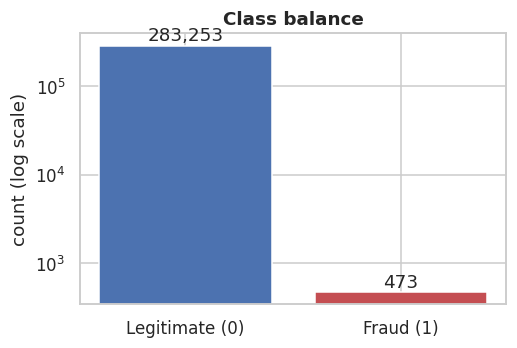

In [4]:
n_fraud, n = int(df.Class.sum()), len(df)
print(f"fraud: {n_fraud} / {n} = {100*n_fraud/n:.3f} %  (1 fraud per {n/n_fraud:.0f} transactions)")
print(f"accuracy of a model that NEVER flags fraud: {100*(1-n_fraud/n):.3f} %")

fig, ax = plt.subplots(figsize=(5, 3.2))
counts = df.Class.value_counts().sort_index()
ax.bar(["Legitimate (0)", "Fraud (1)"], counts.values, color=[C_LEGIT, C_FRAUD])
ax.set_yscale("log")
for i, v in enumerate(counts.values):
    ax.text(i, v * 1.15, f"{v:,}", ha="center")
ax.set(ylabel="count (log scale)", title="Class balance")
savefig("01_class_balance"); plt.show()

A model that never flags anything is **99.83 % accurate** and catches zero fraud. The project therefore reports
triage metrics instead:
* **PR-AUC** (average precision): how well the score ranks frauds above legitimate rows when positives are rare;
* **Recall at a fixed false-positive budget**: e.g. if we may wrongly flag at most 0.1 % of good customers, what share
  of fraud do we catch?
* **Precision at a review capacity**: if analysts can open only *k* alerts, how many of them are real fraud?

## 3. Time: from a timestamp to a time-of-day signal
`Time` is seconds since the first transaction in the file (0 → 172,792 s ≈ 48 h). The raw value only says *where in
the two-day window* a row sits. That is meaningless for a new transaction and leaky under a time-based split.
The useful part is the **hour of day**.

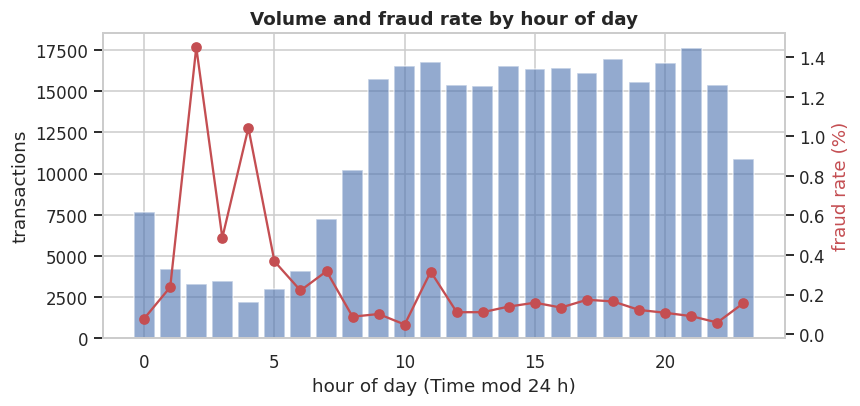

,transactions,frauds,fraud_rate_%
hour_bin,,,
2,3308,48,1.451
4,2204,23,1.044
3,3487,17,0.488
5,2988,11,0.368
7,7233,23,0.318


In [5]:
d = add_features(df)
d["hour_bin"] = d["hour"].astype(int)
by_hour = d.groupby("hour_bin").agg(transactions=("Class", "size"), frauds=("Class", "sum"))
by_hour["fraud_rate_%"] = 100 * by_hour.frauds / by_hour.transactions

fig, ax1 = plt.subplots(figsize=(8, 3.6))
ax1.bar(by_hour.index, by_hour.transactions, color=C_LEGIT, alpha=.6, label="transactions")
ax1.set(xlabel="hour of day (Time mod 24 h)", ylabel="transactions")
ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour["fraud_rate_%"], color=C_FRAUD, marker="o", label="fraud rate %")
ax2.set_ylabel("fraud rate (%)", color=C_FRAUD); ax2.grid(False)
ax1.set_title("Volume and fraud rate by hour of day")
savefig("01_time_of_day"); plt.show()
by_hour.sort_values("fraud_rate_%", ascending=False).head(5).round(3)

Volume drops sharply in the early hours (≈ 01:00–07:00, assuming `Time` = 0 is midnight), while the **fraud rate in
those hours is several times higher**. So the hour carries signal. It is encoded on the unit circle so that 23:00
and 00:00 are neighbours:
$$\text{hour\_sin} = \sin\!\left(\tfrac{2\pi\,h}{24}\right),\qquad \text{hour\_cos} = \cos\!\left(\tfrac{2\pi\,h}{24}\right),\qquad h = (\text{Time} \bmod 86400)/3600.$$

## 4. Amount: heavy right skew → log transform

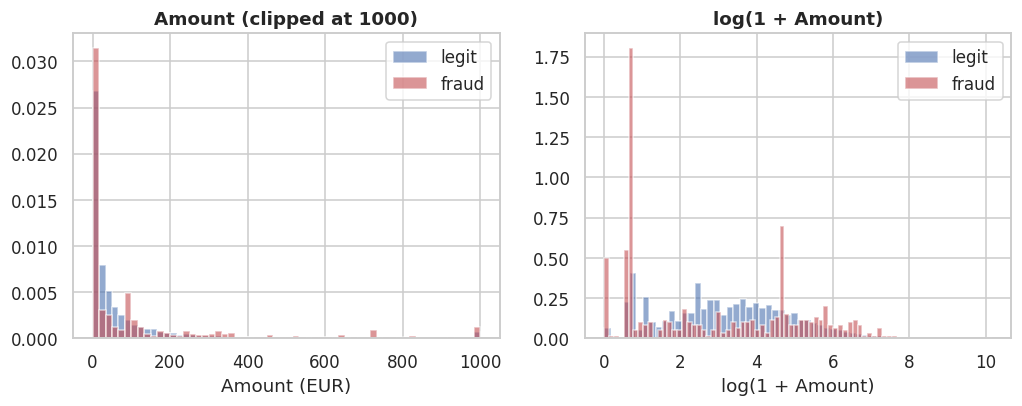

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for cls, c, lab in [(0, C_LEGIT, "legit"), (1, C_FRAUD, "fraud")]:
    sub = d[d.Class == cls]
    axes[0].hist(sub.Amount.clip(upper=1000), bins=60, color=c, alpha=.6, density=True, label=lab)
    axes[1].hist(sub.log_amount, bins=60, color=c, alpha=.6, density=True, label=lab)
axes[0].set(title="Amount (clipped at 1000)", xlabel="Amount (EUR)")
axes[1].set(title="log(1 + Amount)", xlabel="log(1 + Amount)")
for a in axes: a.legend()
savefig("01_amount"); plt.show()
d.groupby("Class").Amount.describe().round(2)

`Amount` ranges from 0 to about 25,700 with skewness > 15. Large values would dominate any distance- or variance-based
model, so we use $\log(1+\text{Amount})$. Frauds have a **lower median** amount but a long tail. Many frauds are
small "test" charges, so amount alone cannot separate the classes.

## 5. Which PCA components differ between classes?
Labels are used here **only for analysis**. The models in Notebooks 02–04 never see them during training. We rank
features by the two-sample Kolmogorov–Smirnov (KS) statistic between the legitimate and fraud distributions.

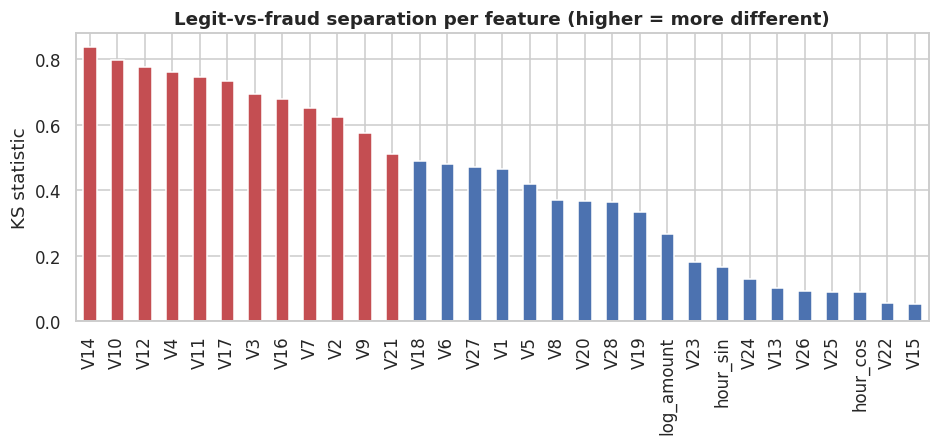

,0
V14,0.838
V10,0.797
V12,0.777
V4,0.761
V11,0.747
V17,0.736
V3,0.695
V16,0.678


In [7]:
from scipy.stats import ks_2samp, skew, kurtosis

feat_cols = V_COLS + ["log_amount", "hour_sin", "hour_cos"]
ks = pd.Series({c: ks_2samp(d.loc[d.Class == 0, c], d.loc[d.Class == 1, c]).statistic for c in feat_cols}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 3.4))
ks.plot.bar(ax=ax, color=[C_FRAUD if v > .5 else C_LEGIT for v in ks.values])
ax.set(ylabel="KS statistic", title="Legit-vs-fraud separation per feature (higher = more different)")
savefig("01_ks_separation"); plt.show()
ks.head(8).round(3)

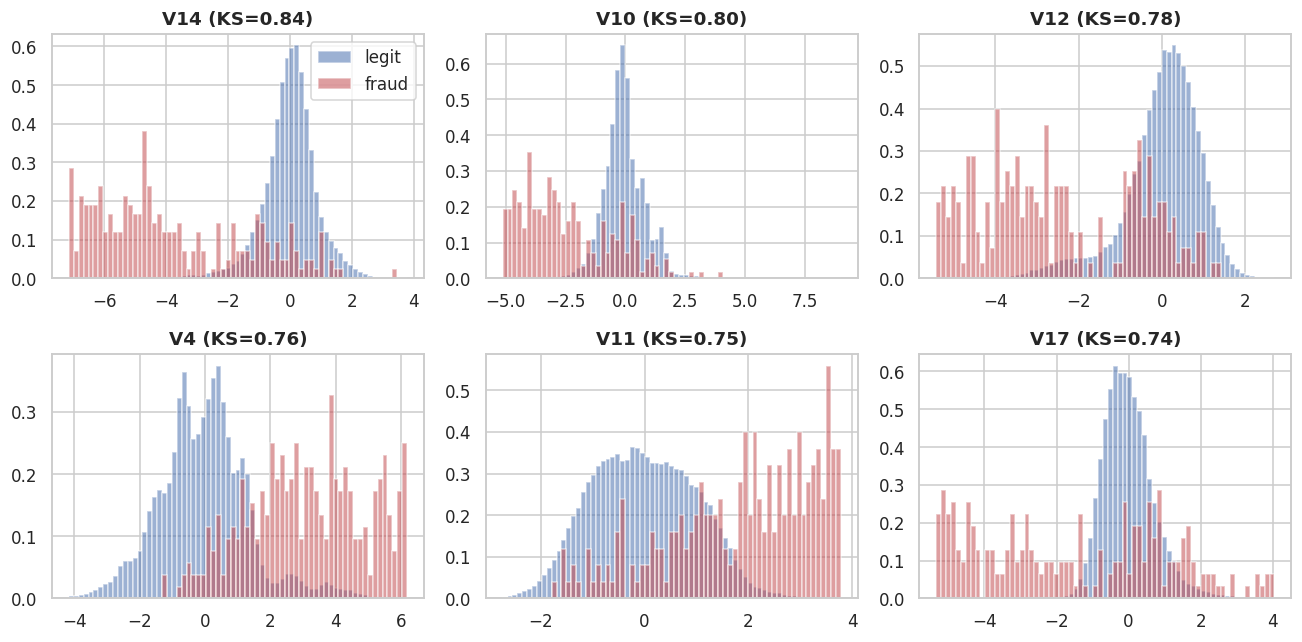

In [8]:
top = ks.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axes.ravel(), top):
    lo, hi = d[c].quantile([.001, .999])
    bins = np.linspace(lo, hi, 70)
    ax.hist(d.loc[d.Class == 0, c], bins=bins, density=True, alpha=.55, color=C_LEGIT, label="legit")
    ax.hist(d.loc[d.Class == 1, c], bins=bins, density=True, alpha=.55, color=C_FRAUD, label="fraud")
    ax.set_title(f"{c} (KS={ks[c]:.2f})")
axes[0, 0].legend()
plt.tight_layout(); savefig("01_top_features"); plt.show()

Frauds sit in the **tails** of several components (V14, V10, V12, V4, V11, V17, ...): far from where legitimate
transactions concentrate. This is exactly the structure that density-based and reconstruction-based anomaly
detectors are designed to exploit. A transaction in a low-density region of "normal" space should be suspicious.

## 6. Are legitimate transactions Gaussian? (motivation for the GMM *and* its gap)
A single Gaussian assumes symmetric, light-tailed marginals (skewness 0, excess kurtosis 0). A mixture of Gaussians
can model multi-modal or skewed shapes, but each component is still Gaussian. We measure how far the legitimate
data is from Gaussian.

In [9]:
legit = d[d.Class == 0]
gauss = pd.DataFrame({"skewness": legit[feat_cols].apply(skew), "excess_kurtosis": legit[feat_cols].apply(kurtosis)})
print("features with |skew| > 1:", int((gauss.skewness.abs() > 1).sum()), "/", len(gauss))
print("features with excess kurtosis > 3:", int((gauss.excess_kurtosis > 3).sum()), "/", len(gauss))
gauss.sort_values("excess_kurtosis", ascending=False).head(10).round(2)

features with |skew| > 1: 13 / 31
features with excess kurtosis > 3: 18 / 31


,skewness,excess_kurtosis
V28,11.63,966.41
V7,4.79,456.60
V23,-5.78,445.82
V20,-2.08,275.24
V27,-0.70,266.48
V5,-2.22,219.37
V8,-8.50,213.17
V21,3.00,178.02
V2,-4.92,99.25
V6,1.85,43.14


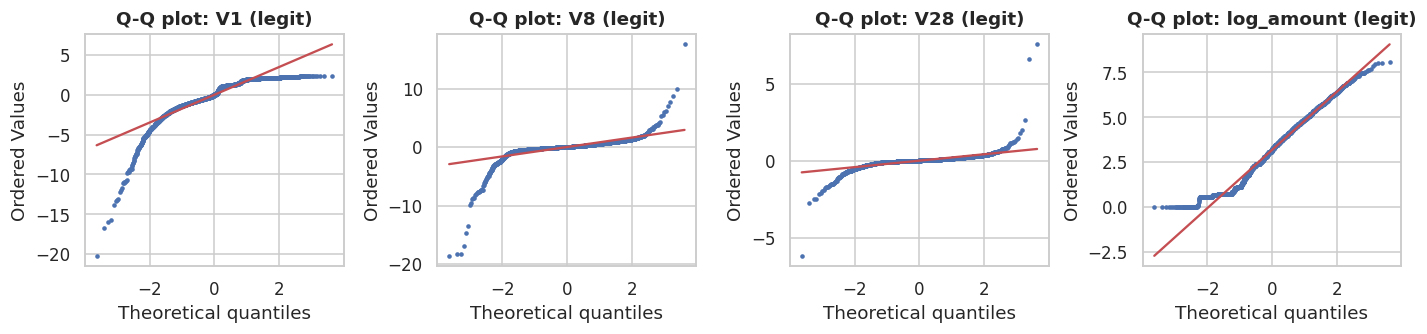

In [10]:
from scipy import stats
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
rng = np.random.default_rng(SEED)
for ax, c in zip(axes, ["V1", "V8", "V28", "log_amount"]):
    sample = rng.choice(legit[c].values, 5000, replace=False)
    stats.probplot(sample, dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {c} (legit)"); ax.get_lines()[0].set_markersize(2)
plt.tight_layout(); savefig("01_qq_plots"); plt.show()

Most legitimate features are **heavy-tailed and/or skewed**: the Q-Q points bend away from the straight line.
* A single Gaussian (= Mahalanobis distance) is a poor fit, which is why we use a **mixture** whose number of
  components is chosen by AIC/BIC.
* Even a mixture approximates curved, heavy-tailed shapes only by adding many components. In 31 dimensions each
  full-covariance component costs 31 + 496 = 527 parameters. This is the **gap** the project brief names: *the
  Gaussian-mixture assumption and instability in high dimensions*. Phase 2 addresses it with a learned non-linear
  model (autoencoder).

## 7. Correlation structure

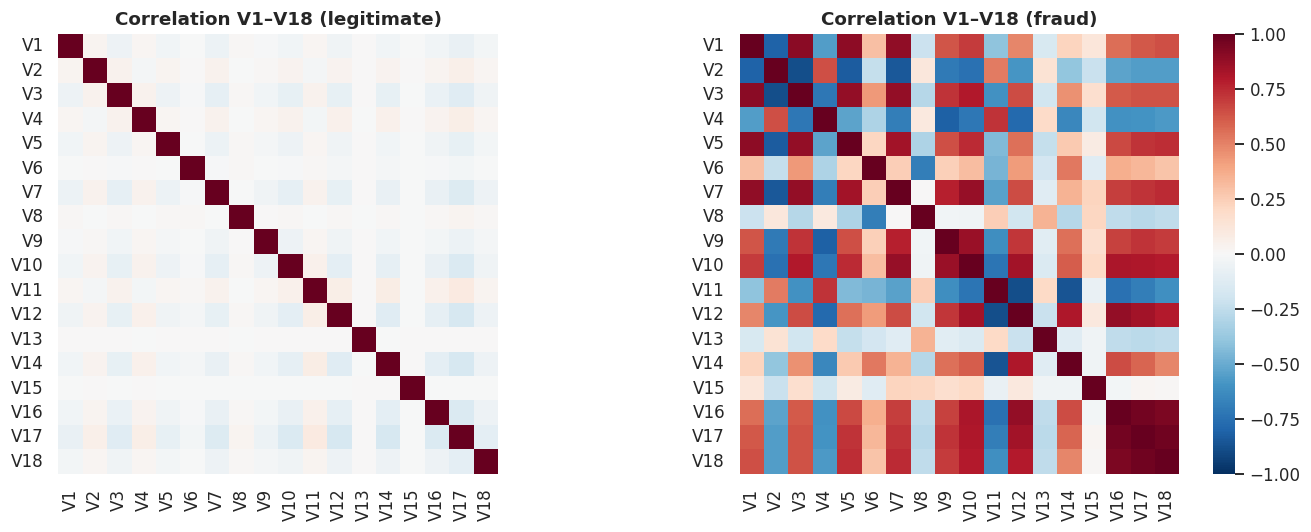

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cls, t in [(axes[0], 0, "legitimate"), (axes[1], 1, "fraud")]:
    sns.heatmap(d.loc[d.Class == cls, V_COLS[:18]].corr(), ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, cbar=cls == 1, square=True)
    ax.set_title(f"Correlation V1–V18 ({t})")
plt.tight_layout(); savefig("01_correlation"); plt.show()

Because the V features are PCA components, they are almost **uncorrelated over the full dataset**. Among frauds,
however, they are strongly correlated: fraud moves several components *together* (e.g. V1–V3, V9–V12, V14–V17).
A full-covariance density model (or a non-linear autoencoder) can notice a combination that is unusual even when no
single feature is extreme. A per-feature threshold rule could not.

## 8. Chronological split and base rates
The brief asks for a time-ordered split. The models are trained on the past and evaluated on the future, as in
production.

| Block | Rows (time order) | Used for |
|---|---|---|
| **Train** (first 60 %) | legitimate rows only | fitting the scaler, the GMM, the autoencoder |
| **Validation** (next 20 %) | mixed | choosing hyper-parameters and **thresholds** |
| **Test** (last 20 %) | mixed, untouched | reported once at the end |

In [12]:
train, val, test = chronological_split(df)
rates = pd.DataFrame([{"split": nme, "rows": len(p), "legit": int((p.Class == 0).sum()), "frauds": int(p.Class.sum()),
                       "fraud_rate_%": 100 * p.Class.mean(), "start_h": p.Time.min() / 3600, "end_h": p.Time.max() / 3600}
                      for nme, p in [("train", train), ("val", val), ("test", test)]])
rates.round(3)

,split,rows,legit,frauds,fraud_rate_%,start_h,end_h
0,train,170236,169894,342,0.201,0.000,33.442
1,val,56745,56688,57,0.100,33.443,40.343
2,test,56745,56671,74,0.130,40.343,47.998


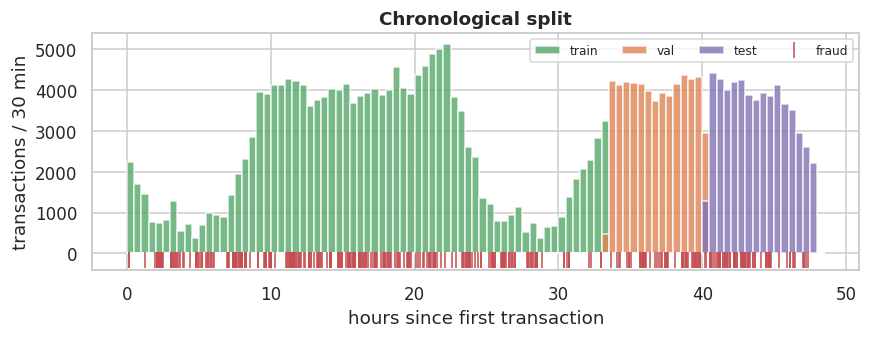

In [13]:
fig, ax = plt.subplots(figsize=(9, 2.8))
for (nme, p), col in zip([("train", train), ("val", val), ("test", test)], ["#55A868", "#DD8452", "#8172B3"]):
    ax.hist(p.Time / 3600, bins=np.arange(0, 49, .5), color=col, alpha=.8, label=nme)
fr = df[df.Class == 1]
ax.plot(fr.Time / 3600, np.full(len(fr), -150), "|", color=C_FRAUD, ms=10, label="fraud")
ax.set(xlabel="hours since first transaction", ylabel="transactions / 30 min", title="Chronological split")
ax.legend(ncol=4, fontsize=8)
savefig("01_split_timeline"); plt.show()

**Base rates differ between blocks** (0.20 % in train, 0.10 % in validation, 0.13 % in test). This drift is
realistic, and it is one reason precision must always be read against the block's base rate. The PR curves in
later notebooks draw this base rate as the "random ranking" line.

**Limitation to keep in mind.** Validation and test (hours 33–48) cover the *daytime and evening* of day 2. The
night-time hours where the fraud *rate* peaks occur only in the training block. The time-of-day feature is therefore
tested only on daytime transactions.

Only **legitimate train rows** (≈ 170 k) are used to fit the models. The label is used once, to *remove* fraud from
the training block (the "legitimate-only" protocol in the brief). After that, the models never see a label.

## 9. Feature engineering summary and leakage checklist

In [14]:
pre = Preprocessor("full", "standard").fit(add_features(train[train.Class == 0]))
X_tr = pre.transform(add_features(train[train.Class == 0]))
X_te = pre.transform(add_features(test))
print("model input dimension:", X_tr.shape[1])
print("train-legit mean/std after scaling (should be 0/1):", X_tr.mean().round(4), X_tr.std().round(4))
print("test mean/std (not exactly 0/1 -> scaler was not fitted on test):", X_te.mean().round(4), X_te.std().round(4))

model input dimension: 31
train-legit mean/std after scaling (should be 0/1): 0.0 1.0
test mean/std (not exactly 0/1 -> scaler was not fitted on test): -0.0691 1.0359


| Step | Choice | Reason |
|---|---|---|
| Duplicates | dropped before splitting | avoid train/test leakage |
| `Time` | → `hour_sin`, `hour_cos`; raw value dropped | keeps the time-of-day signal (night fraud), removes the position-in-file artefact |
| `Amount` | → `log(1+Amount)` | removes extreme skew so one feature cannot dominate |
| `V1`–`V28` | kept | already decorrelated PCA scores |
| Scaling | StandardScaler fitted on **legitimate train rows only** (alternatives compared in Notebook 02) | no information from validation/test or from fraud |
| Split | chronological 60/20/20 | train on past, test on future |
| Labels | used only to drop fraud from train, pick thresholds on validation, and score test | the brief: "keep the fraud label hidden during unsupervised training" |

Three feature sets are compared in Notebook 02: `pca` (V1–V28), `pca+amount`, and `full` (+ hour). Four scalers are
compared too: standard, robust, Yeo-Johnson power, and quantile-normal.

In [15]:
save_json({"data_info": info, "base_rates": rates.to_dict("records"),
           "ks_top10": ks.head(10).round(4).to_dict(),
           "n_skewed": int((gauss.skewness.abs() > 1).sum()), "n_heavy_tailed": int((gauss.excess_kurtosis > 3).sum())},
          "01_eda_summary.json")
finish_colab("outputs_01_eda")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>